In [68]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from os import listdir
from os.path import isfile, join
import re
plt.style.use('seaborn')

In [22]:
# Set variables
BUILD_PATH = "../build"
PROBLEM_PATH = "../problems/pure_int_bench"
TOTAL_TIME = "total time"
NUMBER_CUTS = "number of added cuts"
TOTAL_ROOT_TIME = "Total (root+branch&cut)"

In [3]:
# Get problem names
problem_set = [f for f in listdir(PROBLEM_PATH)
                 if isfile(join(PROBLEM_PATH, f)) and ":Zone.Identifier" not in f]

In [4]:
# Get folder with results
folder = join(BUILD_PATH, input())

In [6]:
# Get worked problems
worked_problems = [problem for problem in problem_set if isfile(join(folder, problem + "_cuts.txt"))]
baseline_files = [problem + "_b_log.txt" for problem in worked_problems]
not_baseline_files = [problem + "_log.txt" for problem in worked_problems]

In [7]:
def set_dict(problems : list) -> dict:
    data = {}
    for p in problems:
        data[p] = {}
        for b in ["base", "no_base"]:
            data[p]["base"] = {}
            data[p]["no_base"] = {}
            if b == "no_base":
                for value in [TOTAL_TIME, TOTAL_ROOT_TIME, NUMBER_CUTS]:
                    data[p][b][value] = 0
            else:
                data[p][b][TOTAL_ROOT_TIME] = 0
    return data

In [105]:
def parser(filename : str, baseline : bool):
    numbers = "\d+\.*?\d+"
    substring = ""
    with open(join(folder, filename)) as f:
        text = f.read()
        if baseline:
            substring += text[text.find(TOTAL_ROOT_TIME) : text.find('sec', text.find(TOTAL_ROOT_TIME))]
            list_numbers = re.findall(numbers, substring)
            return float(list_numbers[0]) if len(list_numbers) else -1
        else:
            for pattern in [TOTAL_TIME, NUMBER_CUTS]:
                i = text.find(pattern)
                j = text.find('\n', i)
                substring += text[i:j]
            substring += text[text.find(TOTAL_ROOT_TIME) : text.find('sec', text.find(TOTAL_ROOT_TIME))]
            list_numbers = re.findall(numbers, substring)
            if len(list_numbers) < 3:
                list_numbers += [-1] * (3 - len(list_numbers))
            list_numbers = list(map(lambda x : round(float(x), 2), list_numbers))
            return list_numbers

In [107]:
data = set_dict(worked_problems)
# Get data
for i, problem in enumerate(worked_problems):
    tot_time, num_cuts, tot_root_time = parser(not_baseline_files[i], False)
    total_root_time_b = parser(baseline_files[i], True)
    data[problem]["base"][TOTAL_ROOT_TIME] = total_root_time_b
    data[problem]["no_base"][TOTAL_TIME] = tot_time
    data[problem]["no_base"][NUMBER_CUTS] = num_cuts
    data[problem]["no_base"][TOTAL_ROOT_TIME] = tot_root_time

In [108]:
def data_table():
    # plt.figure(figsize=(15, 10))
    # X = [problem for problem in data]
    # y = [float(data[p]["no_base"][TOTAL_TIME]) for p in X]
    # plt.title("Total time")
    # plt.bar(x=X, height=y)
    df_data = {p:[data[p]["no_base"][TOTAL_TIME], data[p]["no_base"][NUMBER_CUTS]] for p in data}
    df = pd.DataFrame(data=df_data, index = ["total time", "number of added cuts"])
    return df

In [56]:
# def graph_number_cuts():
#     X = [problem in data]
#     y = [data[p]["no_base"][NUMBER_CUTS] for p in X]
#     plt.title("Number of added cuts")
#     plt.bar(x=X, height=y)

In [114]:
def graph_total_root_time(problem : str):
    X = ["baseline", "not baseline"]
    y = [data[problem]["base"][TOTAL_ROOT_TIME], data[problem]["no_base"][TOTAL_ROOT_TIME]]
    plt.figure(figsize=(15, 10))
    plt.title(problem)
    plt.bar(x=X, height=y, color=["red", "green"])

In [109]:
data_table().head()

,supportcase30.mps.gz,enlight_hard.mps.gz,cod105_vc1024.mps.gz,seymour.mps.gz,pb-market-split8-70-4.mps.gz,sorrell3.mps.gz,glass-sc.mps.gz,neos859080.mps.gz,reblock115.mps.gz
total time,101.03,0.14,107.94,38.12,0.03,3.88,0.24,0.08,28.08
number of added cuts,654.00,104.00,947.00,782.00,60.00,610.00,136.00,10.00,962.00


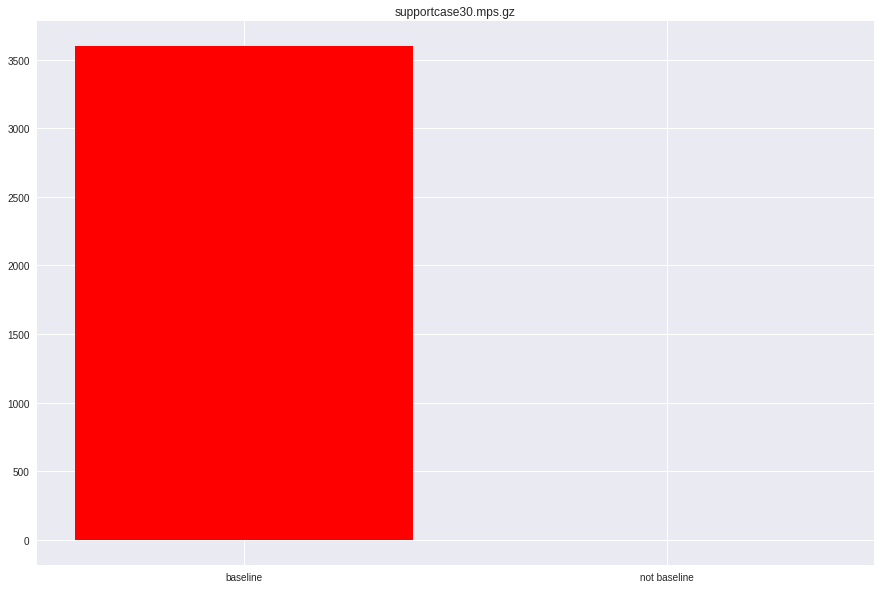

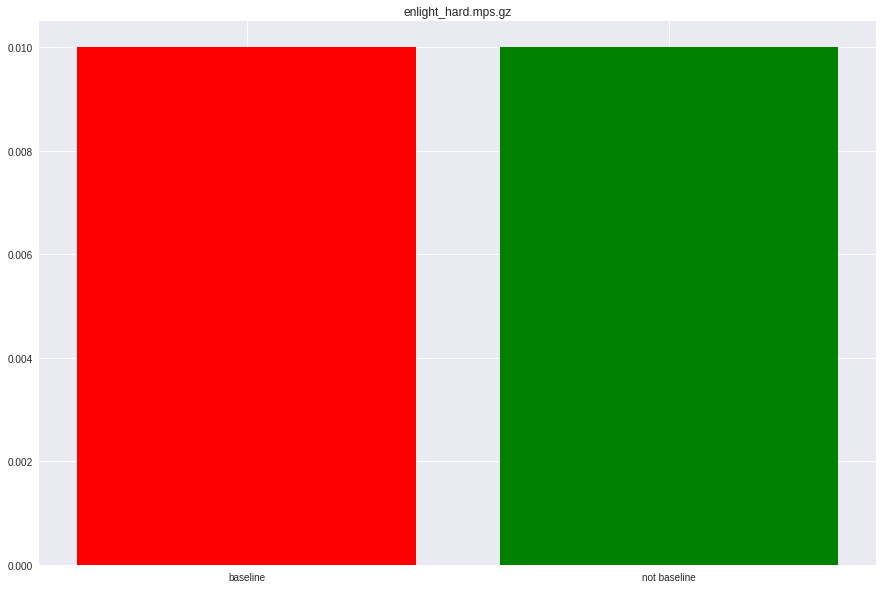

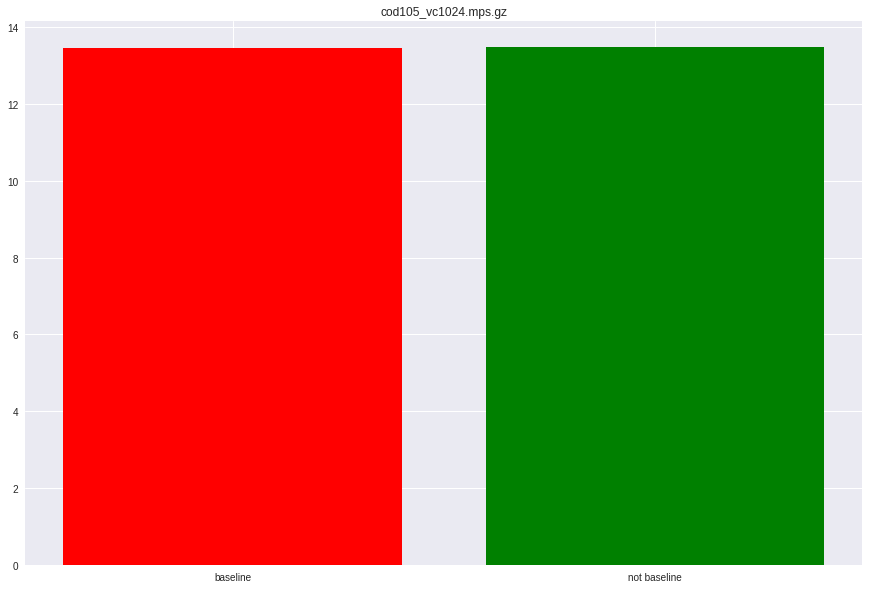

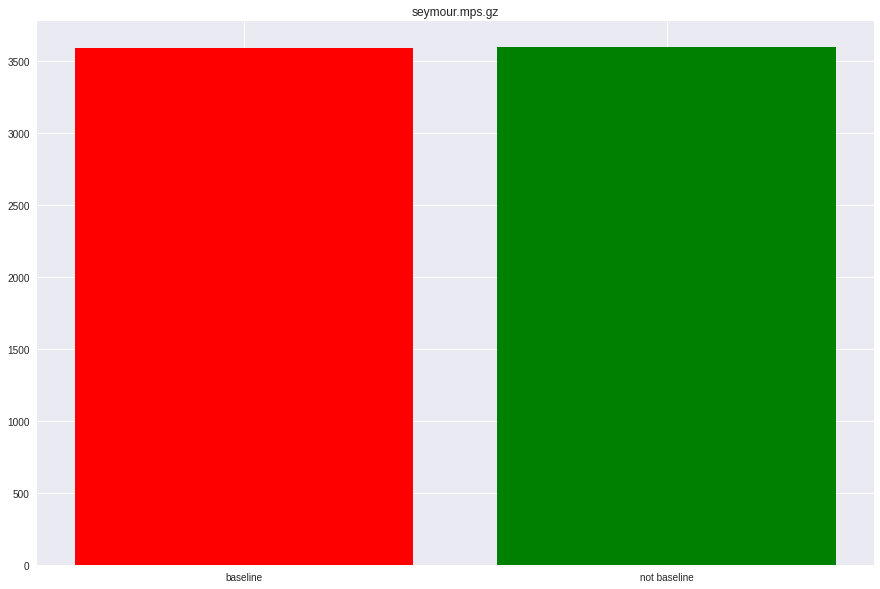

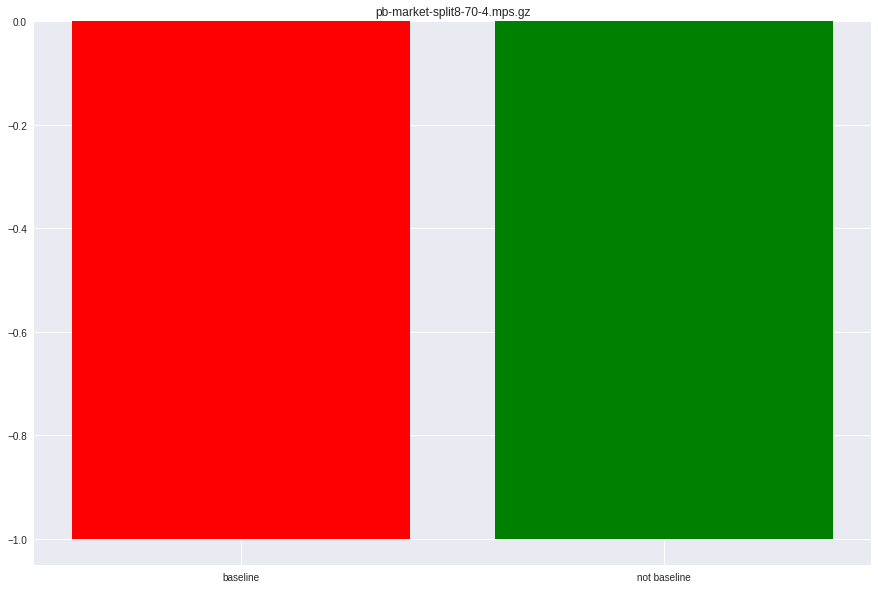

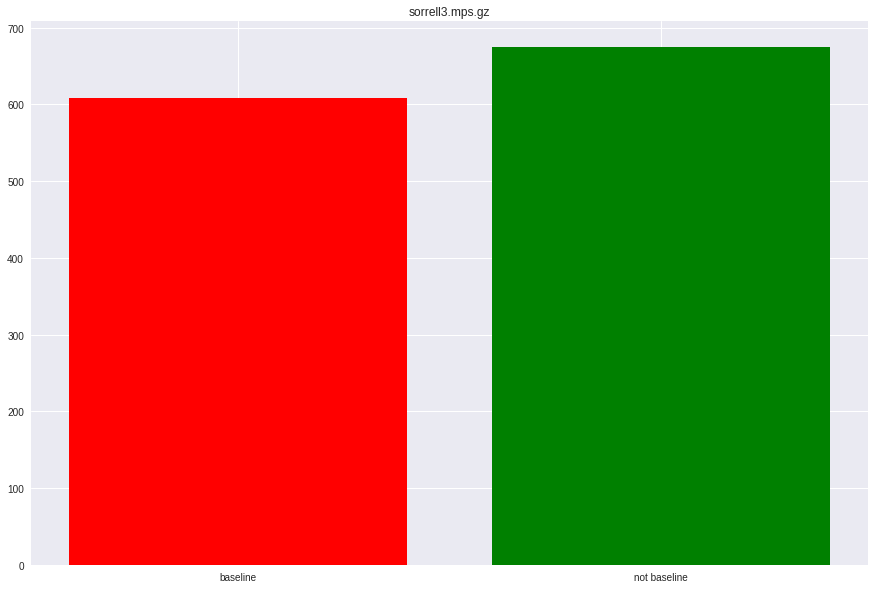

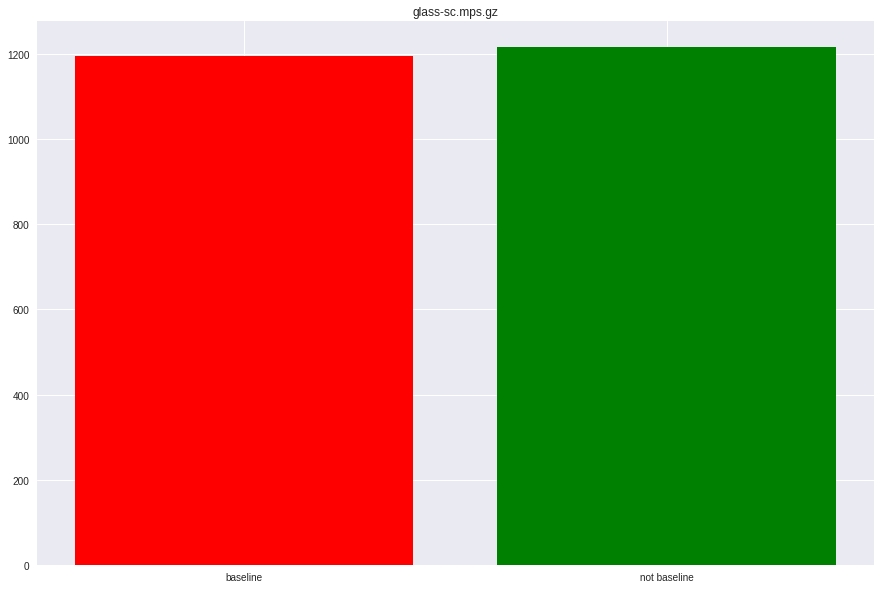

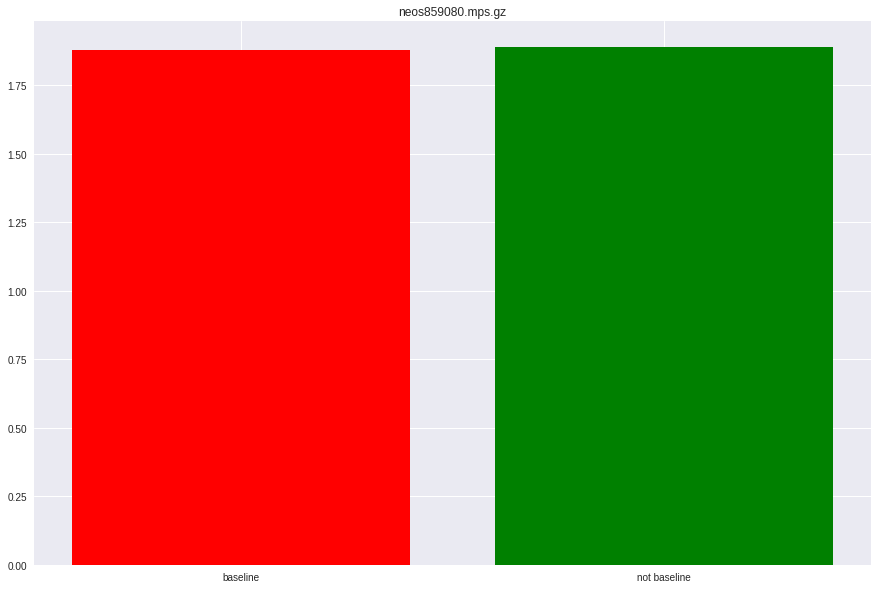

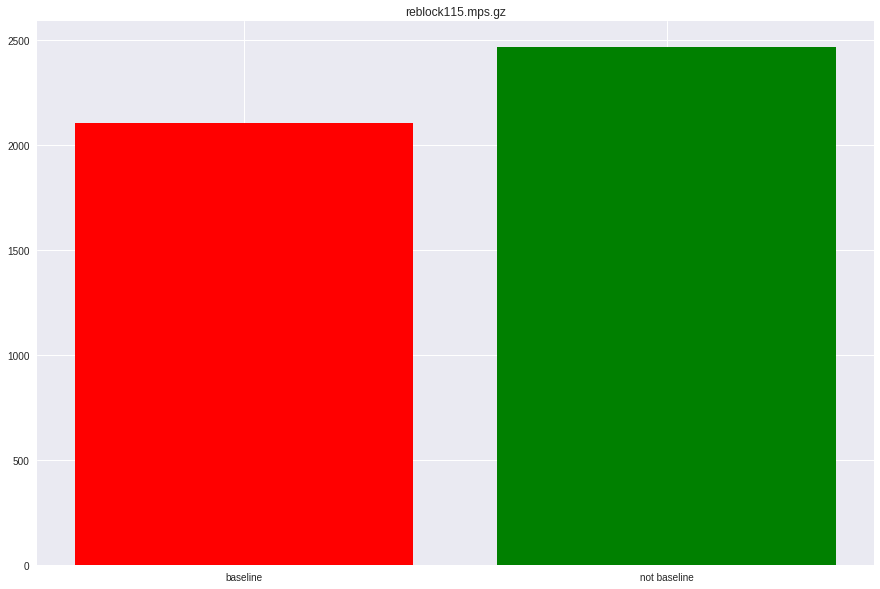

In [115]:
for problem in worked_problems:
    graph_total_root_time(problem)